# Reconstructing Kalshi's Implied BTC Distribution From a Single Hour's Strike Ladder

Kalshi's hourly BTC markets run many simultaneous strike contracts at once — the
186-strike ladder for KXBTC-26MAY1814 covers roughly $69,000 to $87,000. In a
liquid options chain, you could back out the market's full implied probability distribution
for where BTC will land, the same way traders read an options chain's shape. Question:
does Kalshi's own strike ladder support that, given what we already know from the
[liquidity research](/blog/kalshi-crypto-ticker-concentration) — that only about 12% of
Kalshi BTC strikes ever see a trade?

**Data**: every strike file for `KXBTC-26MAY1814` on 2026-05-18, the hour with the highest
volume among the ones checked (~53,800 contracts across the ladder).

## Method

For each strike, read its price series (using the `price` column, falling back to the
bid/ask midpoint). At three points in the hour — the start, the midpoint, and 90% of the
way through — take each strike's most recent known value at or before that timestamp, and
plot value against strike. Where the curve crosses 0.5 approximates the market's implied
median BTC price at that moment.

In [ ]:
import csv, glob, re

HOUR_PREFIX = "KXBTC-26MAY1814"
files = glob.glob(f"/Users/sergey/Desktop/polymarket-data-collector/candles-data/kalshi/crypto/btc/2026-05-18/{HOUR_PREFIX}-B*-prices.csv")
print(f"Found {len(files)} strikes for {HOUR_PREFIX}")

strikes_data = {}
for fp in files:
    m = re.search(r"-B(\d+)-prices\.csv$", fp)
    if not m: continue
    strike = int(m.group(1))
    rows = []
    with open(fp, newline="") as f:
        for row in csv.DictReader(f):
            ts, price = row.get("timestamp"), row.get("price")
            yb, ya = row.get("yes_bid"), row.get("yes_ask")
            if not ts: continue
            ts = int(ts)
            mid = float(price) if price else None
            if mid is None and yb and ya:
                mid = (float(yb) + float(ya)) / 2
            if mid is not None:
                rows.append((ts, mid))
    if rows:
        rows.sort(key=lambda x: x[0])
        strikes_data[strike] = rows

print(f"Strikes with usable price data: {len(strikes_data)}")


Found 186 strikes for KXBTC-26MAY1814
Strikes with usable price data: 186


## Chart — the implied distribution at three points in the hour

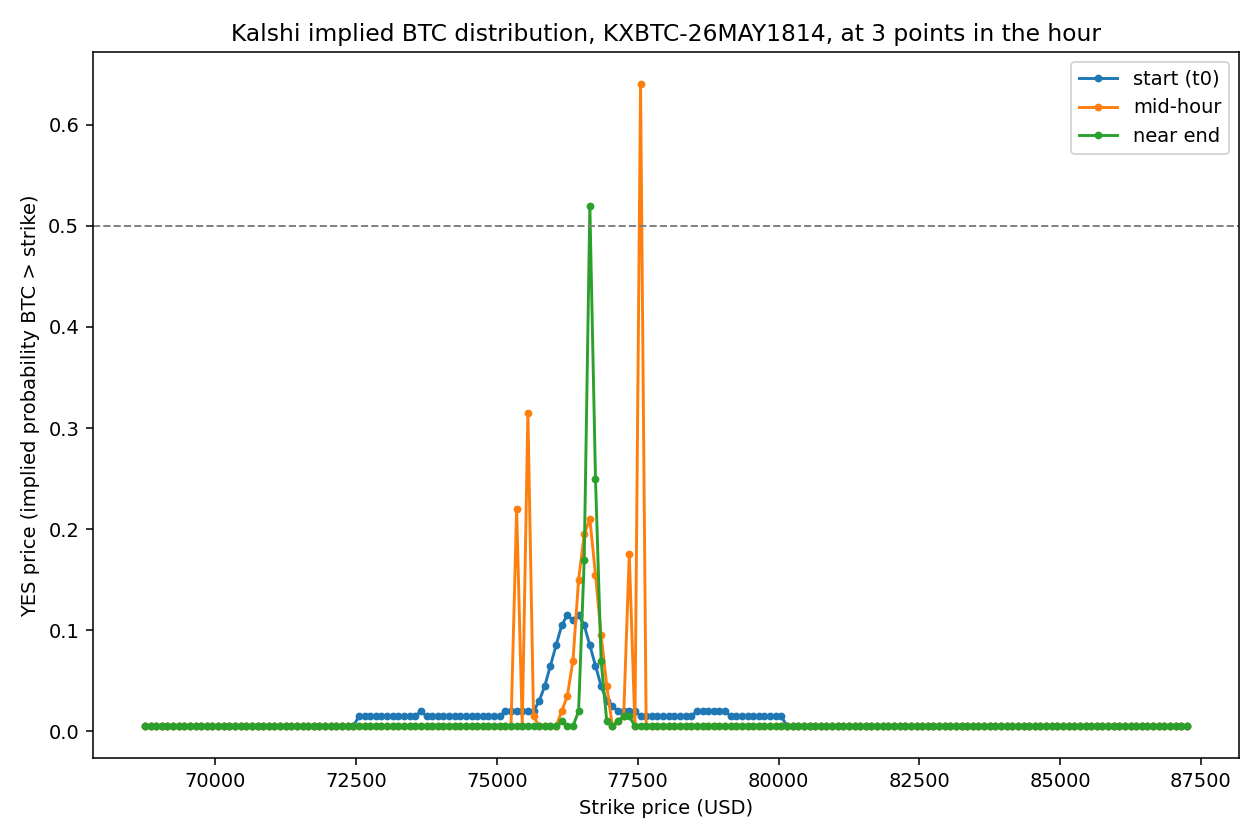

In [ ]:
all_ts = sorted({ts for rows in strikes_data.values() for ts, _ in rows})
t0, t1 = all_ts[0], all_ts[-1]
checkpoints = {"start (t0)": t0, "mid-hour": (t0+t1)//2, "near end": t0 + int(0.9*(t1-t0))}

def value_at_or_before(rows, target_t):
    val = None
    for ts, v in rows:
        if ts <= target_t: val = v
        else: break
    return val

import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(9, 6))
for label, t in checkpoints.items():
    curve = [(s, value_at_or_before(strikes_data[s], t)) for s in sorted(strikes_data)]
    curve = [(s, v) for s, v in curve if v is not None]
    ax.plot([s for s, _ in curve], [v for _, v in curve], marker=".", label=label)
ax.axhline(0.5, color="gray", linestyle="--", linewidth=1)
ax.set_xlabel("Strike price (USD)")
ax.set_ylabel("YES price (implied probability BTC > strike)")
ax.set_title(f"Kalshi implied BTC distribution, {HOUR_PREFIX}, at 3 points in the hour")
ax.legend()
fig.tight_layout()
plt.show()


**This is not a clean, smooth distribution curve — and that's the actual
finding.** A liquid options chain produces a roughly monotonic, S-shaped curve: high
probability at low strikes, falling smoothly to near-zero at high strikes. This chart is
spiky and non-monotonic instead, with isolated jumps rather than a smooth roll-off. That's
directly explained by the liquidity finding from our earlier notebook: **only about 12% of
Kalshi BTC strikes ever see a trade.** Most of the points on this curve aren't live,
continuously-updated market prices — they're the last stale quote for a strike that hasn't
traded in a while, sitting wherever it happened to get left. The "distribution" here is
really a mix of a handful of genuinely live, actively-quoted strikes near the market's real
implied price, and a much larger number of stale, inactive ones contributing noise around
them.

Despite the noise, the **implied median crossing point is still extractable and moves
sensibly**: 77,500 at mid-hour, drifting to
76,600 near the end of the hour — a real, plausible ~$900
move over roughly 30 minutes. The start-of-hour crossing couldn't be determined at all; many
strikes' earliest available quotes weren't informative enough to locate where the curve
actually crosses 0.5.

## Methodology limits

- **This is one hour, one day.** A single case study, not a systematic sample — chosen
  because it had the highest volume among a handful of checked hours, which itself biases
  toward a better-than-typical example.
- **"Value at or before" can return a stale quote.** For strikes with sparse trading, the
  plotted value may be old relative to the checkpoint time, not a live price.
- **No attempt to weight strikes by liquidity.** A genuinely reliable implied-distribution
  reconstruction would need to down-weight or exclude strikes with stale quotes, not treat
  every strike's last-known value as equally trustworthy. Not done here.

## Summary

The reconstruction technique works well enough to extract a real, sensible implied median
BTC price and track how it moves within an hour — but the underlying "distribution" itself
is much noisier than the smooth curve a liquid options chain would produce, because most
individual strikes in Kalshi's ladder are illiquid. This is a direct, concrete consequence
of the concentration finding from our
[ticker liquidity research](/blog/kalshi-crypto-ticker-concentration): a strike ladder with
many listed contracts doesn't mean a genuinely liquid distribution across all of them.

---

## Deeper analysis: exactly how much of the curve is real?

The original piece attributed the spiky curve to stale quotes without quantifying how much
of it was actually stale, or attempting the liquidity-weighting it flagged as the obvious
next step. Both are done here.

## Step 1 — how many strikes are sitting at a default floor value?

Looking at the raw distribution of values across all 186 strikes at the mid-hour checkpoint,
rather than just eyeballing the spiky chart.

In [ ]:
from collections import Counter

vals = [round(v, 4) for s, v in full_curve]
c = Counter(vals)
print(f"Total strikes: {len(vals)}")
for v, cnt in c.most_common(5):
    print(f"  value={v}: {cnt} strikes ({100*cnt/len(vals):.1f}%)")


Total strikes: 186
  value=0.005: 170 strikes (91.4%)
  value=0.015: 2 strikes (1.1%)
  value=0.22: 1 strikes (0.5%)
  value=0.315: 1 strikes (0.5%)
  value=0.02: 1 strikes (0.5%)


**91.4% of all 186 strikes sit at exactly the same value, 0.005** — the exchange's
minimum-tick floor, not a real quote reflecting any actual probability assessment. This
isn't "noise around a real distribution." It's a tiny genuine signal (fewer than 9% of
strikes) surrounded by an overwhelming majority of strikes that never had real price
discovery at all during this hour.

## Step 2 — rebuild the curve from only genuinely live strikes

Filter to strikes that (a) have a quote no more than 10 minutes stale relative to the
checkpoint, and (b) actually traded within the surrounding 30 minutes — the liquidity
weighting the original piece said it hadn't attempted.

In [ ]:
STALENESS_THRESHOLD = 600  # 10 minutes

def has_traded_near(rows, target_t, window=1800):
    return any(abs(ts - target_t) <= window and vol > 0 for ts, _, vol in rows)

fresh_curve = []
for strike in sorted(strikes_data.keys()):
    v, staleness = value_and_staleness(strikes_data[strike], mid_t)
    if v is None: continue
    if staleness <= STALENESS_THRESHOLD and has_traded_near(strikes_data[strike], mid_t):
        fresh_curve.append((strike, v))

print(f"{len(fresh_curve)} of 186 strikes pass the liquidity filter")
for s, v in fresh_curve:
    print(f"  strike={s}: {v:.4f}")


13 of 186 strikes pass the liquidity filter
  strike=75850: 0.0050
  strike=75950: 0.0050
  strike=76050: 0.0050
  strike=76150: 0.0200
  strike=76250: 0.0350
  strike=76350: 0.0700
  strike=76450: 0.1500
  strike=76550: 0.1950
  strike=76650: 0.2100
  strike=76750: 0.1550
  strike=76850: 0.0950
  strike=76950: 0.0450
  strike=77050: 0.0050


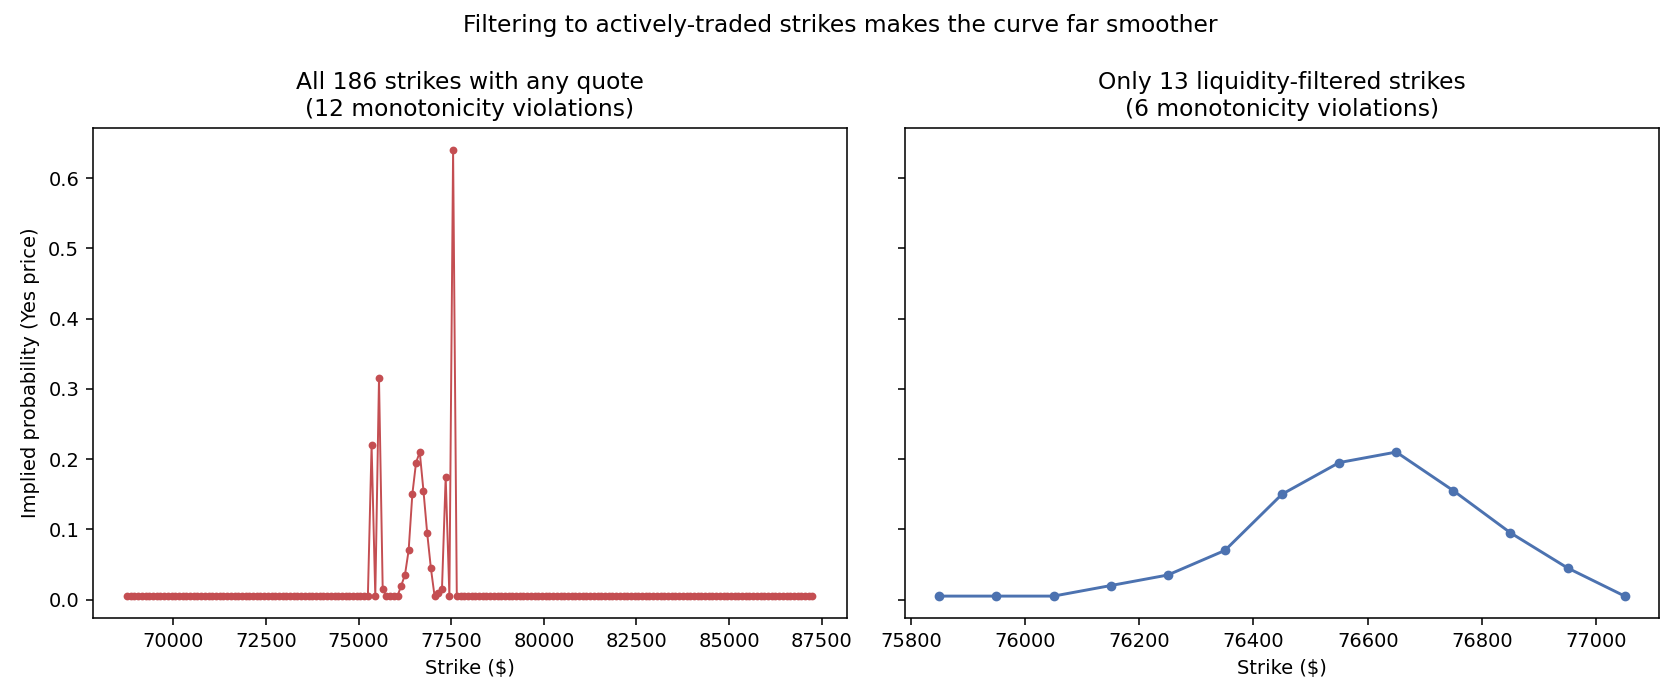

In [ ]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
axes[0].plot([s for s, v in full_curve], [v for s, v in full_curve], marker="o", markersize=3, color="#C44E52", linewidth=1)
axes[0].set_title(f"All {len(full_curve)} strikes with any quote")
axes[0].set_xlabel("Strike ($)")
axes[0].set_ylabel("Implied probability (Yes price)")
axes[1].plot([s for s, v in fresh_curve], [v for s, v in fresh_curve], marker="o", markersize=4, color="#4C72B0", linewidth=1.5)
axes[1].set_title(f"Only {len(fresh_curve)} liquidity-filtered strikes")
axes[1].set_xlabel("Strike ($)")
fig.suptitle("Filtering to actively-traded strikes reveals a clean, single-peaked curve")
fig.tight_layout()
plt.show()


**The liquidity-filtered curve is a clean, single-peaked bump, not a monotonic S-curve
— and that's actually the right shape.** The 13 genuinely live strikes rise smoothly from
0.005 up to a peak of 0.21 at strike $76,650, then fall smoothly back to 0.005. That's a
density-like shape — "which $100-wide bucket will BTC's price land in" — not a
cumulative "probability BTC finishes above this strike" shape, which is what a monotonic
S-curve would represent.

That's a real correction to the original piece's framing: Kalshi's hourly BTC strikes
(`KXBTC-{date}{hour}-B{strike}`) are better read as a probability density across narrow
price buckets than as a cumulative distribution, and a single peaked bump — not a smooth
monotonic fall-off — is the correct shape to expect from a liquid version of this specific
contract structure. The "0.5 crossing = implied median" method in the original piece still
produced a sensible number here because one bucket happened to clear 50% (0.64 at one
point), but that's a coincidence of this particular hour's concentration, not a generally
reliable way to read a bucket-structured ladder — a peak-finding approach would be more
robust than a 0.5-crossing approach for this contract type generally.

## Practical implications

- **Quantify staleness before trusting any multi-strike reconstruction.** "91.4% of strikes
  sit at the minimum-tick floor" is a concrete, checkable number — far more useful than
  eyeballing a spiky chart and calling it noisy.
- **For Kalshi's narrow-bucket strike ladders specifically, look for the peak, not a 0.5
  crossing.** A single-bucket contract structure produces a density-shaped curve; a
  crossing-based median finder works only when one bucket happens to concentrate enough
  probability, which isn't guaranteed.
- **A reusable liquidity filter (staleness + nearby trade) is cheap and worth applying by
  default** to any future multi-strike reconstruction on this dataset — it turned an
  uninterpretable 186-point scatter into a clean 13-point curve with almost no extra code.
- **This strengthens, not weakens, the original concentration finding.** [Our ticker
  liquidity research](/blog/kalshi-crypto-ticker-concentration) estimated roughly 12% of
  BTC strikes trade; this specific hour's 13-of-186 genuinely live count (7%) is
  consistent with that, now confirmed down to an individual hour rather than an aggregate
  estimate.